# Actividad 5.3 — Simulación Monte Carlo de inventarios EOQ

## Parte 1: análisis estadístico de la demanda diaria

**Fuente:** `5.3.- demanda_simulada_tres_ubicaciones_mexico.xlsx` (mismo repositorio).

**Objetivo de esta primera etapa:** partir de los registros de **pedidos individuales**, sumar la demanda de cada ciudad y fecha, y construir las estadísticas y frecuencias relativas acumuladas que utilizaremos en Monte Carlo.

**Importante:** el Excel tiene tres hojas: «Demanda simulada», «Resumen por ubicación» y «Diccionario de datos». **La demanda diaria se obtiene de «Demanda simulada»**, no de los totales de «Resumen por ubicación».

El diccionario indica que los registros abarcan del **1 de enero al 10 de octubre de 2026**, un periodo menor a un año. Para EOQ necesitaremos posteriormente definir cómo estimar la demanda anual D o conseguir un año completo.

**Alcance:** carga de datos, construcción de totales diarios, estadísticas, frecuencias y gráficos. **Todavía no simularemos días futuros ni calcularemos EOQ, ROP o SS.**

## Paso 1. Cargar las bibliotecas

Usamos `pandas` para tablas, `numpy` para operaciones numéricas, `matplotlib` para visualizar los resultados y `display` para mostrar las tablas en Jupyter.

`read_excel()` abrirá el libro que está guardado en la **misma carpeta** que este notebook.

In [27]:
from pathlib import Path
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

## Paso 2. Examinar las hojas y sus columnas

Primero verificamos la estructura del libro. La hoja correcta para estudiar la demanda es **«Demanda simulada»**, que contiene:
- `Cantidad demandada`: unidades de cada pedido.
- `Fecha del pedido`: fecha del pedido.
- `Ubicación`: ciudad.

Una ciudad puede tener **varios pedidos el mismo día**. Por eso hay que sumarlos antes de analizar la demanda diaria.

In [28]:
ARCHIVO = Path("5.3.- demanda_simulada_tres_ubicaciones_mexico.xlsx")

if not ARCHIVO.is_file():
    raise FileNotFoundError(
        f"No encuentro {ARCHIVO.name} en {Path.cwd()}. "
        "Abre el notebook en la carpeta raíz del repositorio y ejecuta git pull."
    )

hojas = pd.read_excel(ARCHIVO, sheet_name=None)

print(f"Archivo: {ARCHIVO.name}")
print(f"Hojas detectadas: {list(hojas)}")

for nombre_hoja, df in hojas.items():
    print(f"\nHOJA: {nombre_hoja}")
    print(f"Filas: {len(df)} | Columnas: {list(df.columns)}")
    display(df.head(5))

Archivo: 5.3.- demanda_simulada_tres_ubicaciones_mexico.xlsx
Hojas detectadas: ['Demanda simulada', 'Resumen por ubicación', 'Diccionario de datos']

HOJA: Demanda simulada
Filas: 1200 | Columnas: ['Cantidad demandada', 'Fecha del pedido', 'Ubicación']


,Cantidad demandada,Fecha del pedido,Ubicación
0,41,2026-01-01,Guadalajara
1,33,2026-01-01,Monterrey
2,54,2026-01-01,Monterrey
3,45,2026-01-02,Ciudad de México
4,33,2026-01-02,Ciudad de México



HOJA: Resumen por ubicación
Filas: 3 | Columnas: ['Ubicación', 'Número de pedidos', 'Demanda total', 'Demanda promedio', 'Demanda mínima', 'Demanda máxima']


,Ubicación,Número de pedidos,Demanda total,Demanda promedio,Demanda mínima,Demanda máxima
0,Ciudad de México,424,17875,42.158019,9,81
1,Guadalajara,408,12136,29.745098,1,54
2,Monterrey,368,13262,36.038043,1,68



HOJA: Diccionario de datos
Filas: 6 | Columnas: ['Campo', 'Descripción']


,Campo,Descripción
0,Cantidad demandada,Unidades demandadas en cada pedido; valores en...
1,Fecha del pedido,Fecha simulada del pedido.
2,Ubicación,"Una de tres ubicaciones: Ciudad de México, Gua..."
3,Número de registros,"1200 pedidos simulados (más de 1,000)."
4,Periodo simulado,Del 01/01/2026 al 10/10/2026.


## Paso 3. Convertir pedidos individuales en demanda diaria por ciudad

Esta es la corrección fundamental respecto a la primera versión del notebook.

Por ejemplo, si Monterrey recibió dos pedidos el 1 de enero, de 33 y 54 unidades, **su demanda diaria es 87 unidades**, no dos días separados.

Agrupamos con `groupby(["Ciudad", "Fecha"]).sum()`. Después generamos una fecha por cada día del periodo estudiado y cada ciudad.

**Supuesto explícito:** consideramos que la hoja registra todos los pedidos realizados en el periodo. Entonces, un día sin pedidos registrados tiene demanda cero. Si el archivo contiene días sin información por otra razón (faltantes o cierres sin registro), habría que tratarlos de otra manera.

Usaremos **días calendario** en esta primera etapa y comprobaremos si el archivo cubre un año completo.

**Nota técnica:** al comparar totales por ciudad, se alinearán los registros por el nombre de la ciudad. No utilizaremos `.equals()` sobre series cuyos índices tengan distintos tipos internos.

In [29]:
# Usamos los pedidos individuales, no el resumen agregado.
pedidos = hojas["Demanda simulada"].copy()

columnas_necesarias = {"Cantidad demandada", "Fecha del pedido", "Ubicación"}
faltantes = columnas_necesarias - set(pedidos.columns)
if faltantes:
    raise ValueError(f"Faltan columnas en 'Demanda simulada': {faltantes}")

pedidos = pedidos.rename(columns={
    "Cantidad demandada": "Demanda",
    "Fecha del pedido": "Fecha",
    "Ubicación": "Ciudad",
})

# Convertir fecha, demanda y ciudad a tipos consistentes.
pedidos["Fecha"] = pd.to_datetime(pedidos["Fecha"], errors="coerce").dt.normalize()
pedidos["Demanda"] = pd.to_numeric(pedidos["Demanda"], errors="coerce")
pedidos["Ciudad"] = pedidos["Ciudad"].astype("string").str.strip()

if pedidos[["Fecha", "Demanda", "Ciudad"]].isna().any().any():
    raise ValueError("Hay pedidos con fecha, ciudad o demanda faltante o inválida.")
if (pedidos["Demanda"] < 0).any():
    raise ValueError("Hay demandas negativas: verifica su significado.")
if not np.allclose(pedidos["Demanda"], pedidos["Demanda"].round()):
    raise ValueError("Hay cantidades no enteras: comprueba las unidades.")

pedidos["Demanda"] = pedidos["Demanda"].astype(int)
if (pedidos["Ciudad"] == "").any():
    raise ValueError("Hay nombres de ciudad vacíos.")

# La suma diaria por ciudad reúne múltiples pedidos del mismo día.
totales_por_dia = (
    pedidos.groupby(["Ciudad", "Fecha"], as_index=False, observed=True)["Demanda"].sum()
)

# Completamos días sin pedidos con demanda cero, bajo el supuesto explicado arriba.
ciudades = sorted(pedidos["Ciudad"].unique().tolist())
calendario = pd.date_range(
    pedidos["Fecha"].min(), pedidos["Fecha"].max(), freq="D"
)
indice_completo = pd.MultiIndex.from_product(
    [ciudades, calendario], names=["Ciudad", "Fecha"]
)

demanda_diaria = (
    totales_por_dia.set_index(["Ciudad", "Fecha"])["Demanda"]
    .reindex(indice_completo, fill_value=0)
    .rename("Demanda")
    .reset_index()
)

print("Ciudades:", ciudades)
print("Pedidos individuales:", len(pedidos))
print(f"Periodo: {calendario.min().date()} a {calendario.max().date()}")
print("Días calendario en el periodo:", len(calendario))
print("Observaciones diarias por ciudad:", len(demanda_diaria) // len(ciudades))

print("\nEjemplo: primeras observaciones diarias")
display(demanda_diaria.head(12))

# Comprobación: al agrupar por día NO se deben perder ni duplicar unidades.
suma_pedidos = pedidos.groupby("Ciudad")["Demanda"].sum().sort_index()
suma_diaria = demanda_diaria.groupby("Ciudad")["Demanda"].sum().sort_index()
comparacion = pd.concat(
    [
        suma_pedidos.rename("Total pedidos"),
        suma_diaria.rename("Total agrupado por día"),
    ],
    axis=1,
)
print("\nVerificación de unidades por ciudad:")
display(comparacion)
assert (
    comparacion.notna().all().all()
    and (comparacion["Total pedidos"] == comparacion["Total agrupado por día"]).all()
), "Error: los totales diarios no coinciden con los pedidos."

# El resumen del Excel se utiliza solo para validar los totales, nunca como demanda diaria.
resumen_excel = hojas["Resumen por ubicación"].set_index("Ubicación")["Demanda total"]
resumen_excel = pd.to_numeric(resumen_excel, errors="raise").sort_index()
comparacion_resumen = pd.concat(
    [
        suma_diaria.rename("Total agrupado por día"),
        resumen_excel.rename("Total hoja resumen"),
    ],
    axis=1,
)
assert (
    comparacion_resumen.notna().all().all()
    and (comparacion_resumen["Total agrupado por día"] == comparacion_resumen["Total hoja resumen"]).all()
), "Los totales no coinciden con la hoja resumen."

if len(ciudades) != 3:
    print("ADVERTENCIA: la actividad pide exactamente tres ciudades.")

if len(calendario) < 365:
    print(
        "\nADVERTENCIA: no hay un año completo de demanda diaria. "
        "Más adelante se debe justificar cómo estimar D anual para EOQ."
    )

print("\nTotales por ciudad verificados contra el resumen del Excel:")
display(suma_diaria.rename("Unidades totales registradas").to_frame())

Ciudades: ['Ciudad de México', 'Guadalajara', 'Monterrey']
Pedidos individuales: 1200
Periodo: 2026-01-01 a 2026-10-10
Días calendario en el periodo: 283
Observaciones diarias por ciudad: 283

Ejemplo: primeras observaciones diarias


,Ciudad,Fecha,Demanda
0,Ciudad de México,2026-01-01,0
1,Ciudad de México,2026-01-02,116
2,Ciudad de México,2026-01-03,111
3,Ciudad de México,2026-01-04,0
4,Ciudad de México,2026-01-05,39
5,Ciudad de México,2026-01-06,0
6,Ciudad de México,2026-01-07,48
7,Ciudad de México,2026-01-08,51
8,Ciudad de México,2026-01-09,84
9,Ciudad de México,2026-01-10,49



Verificación de unidades por ciudad:


,Total pedidos,Total agrupado por día
Ciudad,,
Ciudad de México,17875,17875
Guadalajara,12136,12136
Monterrey,13262,13262



ADVERTENCIA: no hay un año completo de demanda diaria. Más adelante se debe justificar cómo estimar D anual para EOQ.

Totales por ciudad verificados contra el resumen del Excel:


,Unidades totales registradas
Ciudad,
Ciudad de México,17875
Guadalajara,12136
Monterrey,13262


## Paso 4. Estadísticas descriptivas **de la demanda diaria**

Ahora que agrupamos los pedidos por día, calculamos para cada ciudad:

- Días del periodo analizado.
- Media de unidades **por día**.
- Desviación estándar diaria.
- Demanda mínima, máxima y total **registrada en el periodo**.
- Número de días con demanda cero.

**No confundas** el promedio de unidades *por pedido* de la hoja «Resumen por ubicación» con el promedio de unidades *por día* que necesitamos para Monte Carlo y el cálculo del ROP.

La actividad solicita demanda **anual** para EOQ, pero el archivo que tenemos todavía abarca menos de un año. No etiquetaremos el total del periodo como anual.

In [30]:
resumen = (
    demanda_diaria.groupby("Ciudad")["Demanda"]
    .agg(
        Dias_registrados="count",
        Demanda_media_diaria="mean",
        Desviacion_estandar_diaria="std",
        Demanda_minima_diaria="min",
        Demanda_maxima_diaria="max",
        Demanda_total_periodo="sum",
        Dias_demanda_cero=lambda s: (s == 0).sum(),
    )
    .reset_index()
)

print("Resumen estadístico de DEMANDA DIARIA (no de pedidos individuales)")
display(resumen.round(2))
print(
    "\nIMPORTANTE: 'Demanda_total_periodo' no es demanda anual "
    "si no contamos con un año completo de información."
)

Resumen estadístico de DEMANDA DIARIA (no de pedidos individuales)


,Ciudad,Dias_registrados,Demanda_media_diaria,Desviacion_estandar_diaria,Demanda_minima_diaria,Demanda_maxima_diaria,Demanda_total_periodo,Dias_demanda_cero
0,Ciudad de México,283,63.16,49.11,0,214,17875,61
1,Guadalajara,283,42.88,39.96,0,243,12136,68
2,Monterrey,283,46.86,41.85,0,173,13262,75



IMPORTANTE: 'Demanda_total_periodo' no es demanda anual si no contamos con un año completo de información.


## Paso 5. Frecuencias relativas acumuladas de la demanda diaria

Para cada ciudad contamos cuántos días se registró cada nivel de demanda diaria (ya sumados los pedidos del día).

- **Frecuencia absoluta:** cantidad de días con esa demanda.
- **Frecuencia relativa:** frecuencia absoluta dividida entre días estudiados.
- **Frecuencia acumulada:** suma de las frecuencias absolutas.
- **Frecuencia relativa acumulada:** suma de las frecuencias relativas hasta alcanzar 1.

Estas son las distribuciones empíricas que utilizaremos para convertir un número U(0,1) en demanda diaria simulada.

Ejemplo: si la acumulada pasa de 0.30 para 10 unidades a 0.70 para 20 unidades, U = 0.56 produce demanda de 20 unidades.

Las tablas pueden ser extensas porque aquí utilizamos cada valor de demanda, sin agrupar por intervalos.

In [31]:
tablas_frecuencia = {}

for ciudad, grupo in demanda_diaria.groupby("Ciudad"):
    tabla = (
        grupo["Demanda"]
        .value_counts()
        .sort_index()
        .rename_axis("Demanda")
        .reset_index(name="Frecuencia absoluta")
    )

    total_dias = int(tabla["Frecuencia absoluta"].sum())
    tabla["Frecuencia relativa"] = tabla["Frecuencia absoluta"] / total_dias
    tabla["Frecuencia acumulada"] = tabla["Frecuencia absoluta"].cumsum()
    tabla["Frecuencia relativa acumulada"] = tabla["Frecuencia relativa"].cumsum()

    tablas_frecuencia[ciudad] = tabla

    print(f"\n{ciudad}: {total_dias} días, {len(tabla)} niveles distintos de demanda.")
    display(tabla.round(5))

    assert tabla["Frecuencia absoluta"].sum() == total_dias
    assert np.isclose(tabla["Frecuencia relativa"].sum(), 1.0)
    assert np.isclose(tabla["Frecuencia relativa acumulada"].iloc[-1], 1.0)

print("\nTodas las distribuciones empíricas suman 100%.")


Ciudad de México: 283 días, 107 niveles distintos de demanda.


,Demanda,Frecuencia absoluta,Frecuencia relativa,Frecuencia acumulada,Frecuencia relativa acumulada
0,0,61,0.21555,61,0.21555
1,26,1,0.00353,62,0.21908
2,27,3,0.01060,65,0.22968
3,28,2,0.00707,67,0.23675
4,29,1,0.00353,68,0.24028
...,...,...,...,...,...
102,191,1,0.00353,279,0.98587
103,196,1,0.00353,280,0.98940
104,201,1,0.00353,281,0.99293
105,210,1,0.00353,282,0.99647



Guadalajara: 283 días, 97 niveles distintos de demanda.


,Demanda,Frecuencia absoluta,Frecuencia relativa,Frecuencia acumulada,Frecuencia relativa acumulada
0,0,68,0.24028,68,0.24028
1,7,1,0.00353,69,0.24382
2,13,1,0.00353,70,0.24735
3,16,2,0.00707,72,0.25442
4,17,3,0.01060,75,0.26502
...,...,...,...,...,...
92,148,2,0.00707,279,0.98587
93,177,1,0.00353,280,0.98940
94,188,1,0.00353,281,0.99293
95,193,1,0.00353,282,0.99647



Monterrey: 283 días, 104 niveles distintos de demanda.


,Demanda,Frecuencia absoluta,Frecuencia relativa,Frecuencia acumulada,Frecuencia relativa acumulada
0,0,75,0.26502,75,0.26502
1,1,1,0.00353,76,0.26855
2,11,1,0.00353,77,0.27208
3,12,1,0.00353,78,0.27562
4,14,1,0.00353,79,0.27915
...,...,...,...,...,...
99,141,1,0.00353,277,0.97880
100,145,1,0.00353,278,0.98233
101,160,1,0.00353,279,0.98587
102,167,3,0.01060,282,0.99647



Todas las distribuciones empíricas suman 100%.


## Paso 6. Histogramas de la demanda diaria

Ahora graficaremos **unidades demandadas por día** (no unidades por pedido ni totales por ciudad).

En el siguiente paso de la actividad tomaremos los números uniformes U y utilizaremos las frecuencias acumuladas calculadas aquí para generar demandas sintéticas que respeten la distribución empírica de cada ciudad.

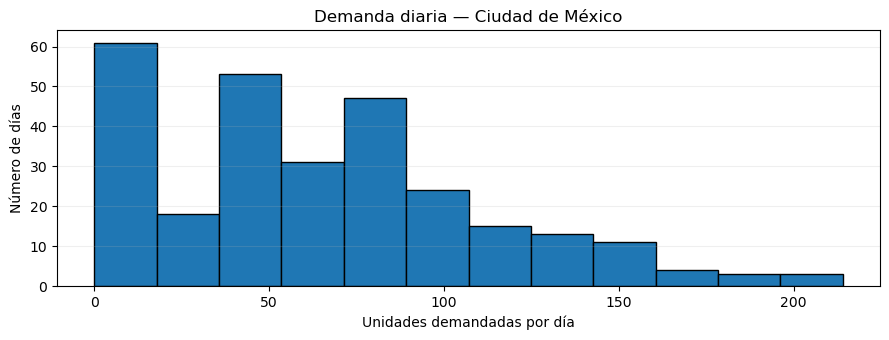

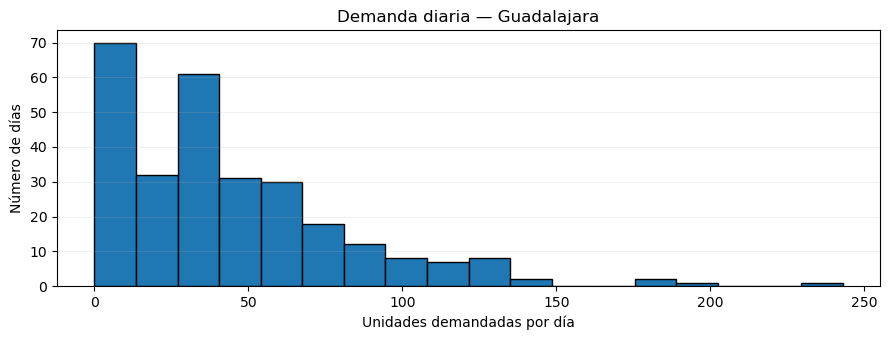

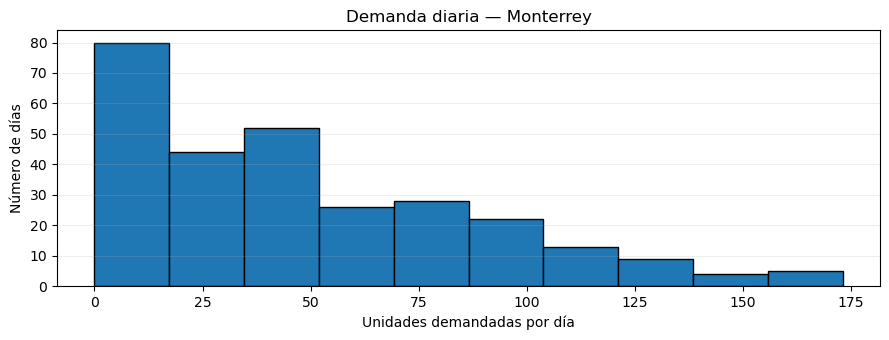

In [32]:
for ciudad, grupo in demanda_diaria.groupby("Ciudad"):
    fig, ax = plt.subplots(figsize=(9, 3.5))
    ax.hist(grupo["Demanda"], bins="auto", edgecolor="black")
    ax.set_title(f"Demanda diaria — {ciudad}")
    ax.set_xlabel("Unidades demandadas por día")
    ax.set_ylabel("Número de días")
    ax.grid(axis="y", alpha=0.2)
    plt.tight_layout()
    plt.show()

## Parte 2. Parámetros del modelo EOQ

En esta sección calcularemos la política de inventarios para cada ciudad antes de generar nuevas demandas Monte Carlo.

## Paso 7. Definir los parámetros del inventario por ciudad

En el **Paso 1.2 del PDF** necesitamos calcular el lote económico (EOQ), el stock de seguridad (SS) y el punto de reorden (ROP).

Para ello utilizaremos los promedios y desviaciones estándar de la demanda diaria que ya obtuvimos. El archivo Excel **no proporciona costos de inventario, plazos de entrega ni inventario inicial**. Por eso la siguiente celda incluye **valores de ejemplo propuestos para la actividad**, que puedes cambiar cuando quieras; **no proceden del Excel ni del profesor**.

| Ciudad | Costo fijo por pedido S (MXN/pedido) | Costo de mantener H (MXN/unidad·año) | Entrega L (días calendario) | Inventario inicial (unidades) | Servicio objetivo |
|---|---:|---:|---:|---:|---:|
| Ciudad de México | 450 | 30 | 5 | 550 | 95 % |
| Guadalajara | 350 | 22 | 4 | 400 | 95 % |
| Monterrey | 400 | 26 | 5 | 450 | 95 % |

### ¿Qué hacer con los 283 días disponibles?

La fórmula del EOQ necesita **demanda anual** `D`. Nuestro Excel representa solo **283 días**, por lo que no podemos llamar «demanda anual» a las unidades de ese periodo.

En esta etapa elegimos una **proyección explícita**:

\[
\widehat D_{\mathrm{anual}}=\bar d\times365
\]

Esto equivale a suponer que la tasa diaria observada se mantiene durante los 365 días de un año. Usaremos **días calendario** de forma consistente para la demanda diaria y el plazo de entrega. Es una aproximación para fines de simulación, no una observación anual real.

> El nivel de servicio del 95 % utiliza \(z=1.645\) como **supuesto de aproximación normal**. Más adelante evaluaremos qué tan bien funciona con nuestra demanda empírica.

In [33]:
# PARÁMETROS EDITABLES — VALORES HIPOTÉTICOS, NO EXTRAÍDOS DEL EXCEL
# Puedes modificar los costos (MXN), los plazos de entrega y el inventario inicial.
# Todos los plazos se expresan en días calendario.

DIAS_POR_ANIO = 365

parametros_ciudad = pd.DataFrame([
    {
        "Ciudad": "Ciudad de México",
        "S": 450.0,           # MXN por pedido
        "H": 30.0,            # MXN por unidad al año
        "L": 5,               # días calendario
        "Inventario_inicial": 550,
        "Nivel_servicio": 0.95,
        "z": 1.645,
    },
    {
        "Ciudad": "Guadalajara",
        "S": 350.0,
        "H": 22.0,
        "L": 4,
        "Inventario_inicial": 400,
        "Nivel_servicio": 0.95,
        "z": 1.645,
    },
    {
        "Ciudad": "Monterrey",
        "S": 400.0,
        "H": 26.0,
        "L": 5,
        "Inventario_inicial": 450,
        "Nivel_servicio": 0.95,
        "z": 1.645,
    },
])

# Verificamos que haya un conjunto completo de parámetros para cada ciudad.
ciudades_datos = set(resumen["Ciudad"])
ciudades_parametros = set(parametros_ciudad["Ciudad"])
assert ciudades_datos == ciudades_parametros, (
    f"Ciudades sin correspondencia. Datos: {ciudades_datos}; "
    f"parámetros: {ciudades_parametros}"
)
assert parametros_ciudad["Ciudad"].is_unique, "Hay ciudades repetidas en los parámetros."
assert (parametros_ciudad[["S", "H"]] > 0).all().all(), "Los costos S y H deben ser positivos."
assert (parametros_ciudad["L"] > 0).all(), "El plazo L debe ser positivo."
assert (parametros_ciudad["Inventario_inicial"] >= 0).all(), "El inventario inicial no puede ser negativo."
assert parametros_ciudad["Nivel_servicio"].between(0, 1, inclusive="neither").all()
assert (parametros_ciudad["z"] > 0).all(), "El factor z debe ser positivo."

print("Parámetros hipotéticos de inventario (modificables):")
display(parametros_ciudad)

Parámetros hipotéticos de inventario (modificables):


,Ciudad,S,H,L,Inventario_inicial,Nivel_servicio,z
0,Ciudad de México,450.0,30.0,5,550,0.95,1.645
1,Guadalajara,350.0,22.0,4,400,0.95,1.645
2,Monterrey,400.0,26.0,5,450,0.95,1.645


## Paso 8. Calcular EOQ, stock de seguridad y punto de reorden

Con los datos diarios de la **parte anterior** y los parámetros que acabamos de establecer:

**1. Proyectamos la demanda anual**

\[
D=\bar d\times365
\]

**2. Calculamos el lote económico** (cuánto pedir)

\[
Q^*=\sqrt{\frac{2DS}{H}}
\]

**3. Calculamos el stock de seguridad** (protección frente a variaciones diarias)

\[
SS=z\sigma_d\sqrt L
\]

Esta última fórmula corresponde a una demanda diaria independiente, con una desviación estándar estable, un plazo de entrega **constante** y una aproximación normal. Nuestra simulación posterior usará la distribución empírica real y nos ayudará a ver los resultados de esta aproximación.

**4. Calculamos el punto de reorden** (cuándo pedir)

\[
ROP=\bar d\,L+SS
\]

**5. Métricas adicionales**

\[
N=\frac{D}{Q},\qquad T=\frac{365}{N}
\]

Aquí \(Q\) representa el **lote entero** que utilizaríamos en la práctica, a partir de \(Q^*\). El plazo \(L\) se mide en días, mientras que \(T\) representa los días promedio **entre pedidos**; son conceptos distintos.

**Redondeo:** para poder pedir unidades enteras, redondearemos \(Q^*\) al entero más cercano, \(SS\) hacia arriba y \(ROP\) hacia arriba. Conservar la versión sin redondear también nos permitirá interpretar mejor las fórmulas.

In [34]:
# Juntamos el resumen de demanda diaria con los parámetros editables.
politicas = resumen.merge(
    parametros_ciudad, on="Ciudad", how="inner", validate="one_to_one"
).copy()

# No debemos tener valores faltantes en los datos relevantes.
variables = [
    "Dias_registrados", "Demanda_media_diaria", "Desviacion_estandar_diaria",
    "S", "H", "L", "Inventario_inicial", "z"
]
if politicas[variables].isna().any().any():
    raise ValueError("Faltan datos para calcular la política de inventario.")
if (politicas["Dias_registrados"] < 2).any():
    raise ValueError("Se requieren al menos 2 días por ciudad para estimar la desviación.")

# 1. Extrapolación de los 283 días disponibles a un año de 365 días.
politicas["D_anual_estimada"] = politicas["Demanda_media_diaria"] * DIAS_POR_ANIO

# 2. Lote económico teórico y lote operativo entero.
politicas["Q_teorico"] = np.sqrt(
    2 * politicas["D_anual_estimada"] * politicas["S"] / politicas["H"]
)
politicas["Q_pedido"] = np.maximum(1, np.rint(politicas["Q_teorico"]).astype(int))

# 3. Stock de seguridad con plazo fijo y demanda diaria variable.
politicas["SS_teorico"] = (
    politicas["z"] * politicas["Desviacion_estandar_diaria"] * np.sqrt(politicas["L"])
)
politicas["SS"] = np.ceil(politicas["SS_teorico"]).astype(int)

# 4. Demanda esperada durante el plazo y posición que dispara un nuevo pedido.
politicas["Demanda_en_entrega"] = politicas["Demanda_media_diaria"] * politicas["L"]
politicas["ROP"] = np.ceil(
    politicas["Demanda_en_entrega"] + politicas["SS"]
).astype(int)

# 5. Cuántos pedidos anuales y cada cuántos días, en promedio.
politicas["Pedidos_al_anio"] = politicas["D_anual_estimada"] / politicas["Q_pedido"]
politicas["Dias_entre_pedidos"] = DIAS_POR_ANIO / politicas["Pedidos_al_anio"]

columnas_resultado = [
    "Ciudad", "D_anual_estimada", "Demanda_media_diaria",
    "Desviacion_estandar_diaria", "S", "H", "L",
    "Q_teorico", "Q_pedido", "SS", "ROP",
    "Pedidos_al_anio", "Dias_entre_pedidos", "Inventario_inicial"
]

print("PARÁMETROS CALCULADOS DEL MODELO EOQ (unidades y MXN):")
display(politicas[columnas_resultado].round(2))

for _, fila in politicas.iterrows():
    print(
        f"\n{fila['Ciudad']}: pedir {int(fila['Q_pedido'])} unidades "
        f"cuando la posición de inventario sea <= {int(fila['ROP'])}. "
        f"Stock de seguridad: {int(fila['SS'])} unidades."
    )

PARÁMETROS CALCULADOS DEL MODELO EOQ (unidades y MXN):


,Ciudad,D_anual_estimada,Demanda_media_diaria,Desviacion_estandar_diaria,S,H,L,Q_teorico,Q_pedido,SS,ROP,Pedidos_al_anio,Dias_entre_pedidos,Inventario_inicial
0,Ciudad de México,23054.33,63.16,49.11,450.0,30.0,5,831.64,832,181,497,27.71,13.17,550
1,Guadalajara,15652.44,42.88,39.96,350.0,22.0,4,705.71,706,132,304,22.17,16.46,400
2,Monterrey,17104.70,46.86,41.85,400.0,26.0,5,725.46,725,154,389,23.59,15.47,450



Ciudad de México: pedir 832 unidades cuando la posición de inventario sea <= 497. Stock de seguridad: 181 unidades.

Guadalajara: pedir 706 unidades cuando la posición de inventario sea <= 304. Stock de seguridad: 132 unidades.

Monterrey: pedir 725 unidades cuando la posición de inventario sea <= 389. Stock de seguridad: 154 unidades.


## Paso 9. Interpretar y estimar los costos anuales de la política

El EOQ clásico equilibra los costos de **ordenar** y de **mantener el inventario de ciclo**.

\[
C_{\mathrm{ordenar}}=\frac{D}{Q}S
\]

\[
C_{\mathrm{mantener,\ ciclo}}=\frac{Q}{2}H
\]

Cuando además mantenemos stock de seguridad, agregamos aproximadamente:

\[
C_{\mathrm{mantener,\ seguridad}}=SS\cdot H
\]

Por tanto, como **estimación anual teórica**:

\[
CT\approx\frac{D}{Q}S+\left(\frac{Q}{2}+SS\right)H
\]

Aquí **no** sumamos costo de compra (el precio unitario no se nos proporcionó), costo de faltantes ni posibles restricciones del proveedor. Además, **los costos anuales teóricos no son todavía los costos simulados**. Estos últimos se calcularán cuando ejecutemos los días de Monte Carlo.

El inventario inicial se reserva para el siguiente paso; no cambia el cálculo del lote óptimo bajo el EOQ clásico.

In [35]:
# Costos teóricos anuales de la política, con el lote Q entero.
politicas["Costo_ordenar_anual"] = (
    politicas["D_anual_estimada"] / politicas["Q_pedido"] * politicas["S"]
)
politicas["Costo_ciclo_anual"] = (
    politicas["Q_pedido"] / 2 * politicas["H"]
)
politicas["Costo_SS_anual"] = politicas["SS"] * politicas["H"]
politicas["Costo_relevante_anual_estimado"] = (
    politicas["Costo_ordenar_anual"]
    + politicas["Costo_ciclo_anual"]
    + politicas["Costo_SS_anual"]
)

costos_columnas = [
    "Ciudad", "Costo_ordenar_anual", "Costo_ciclo_anual",
    "Costo_SS_anual", "Costo_relevante_anual_estimado"
]

print("COSTOS ANUALES TEÓRICOS ESTIMADOS (MXN):")
display(politicas[costos_columnas].round(2))

# Esta tabla será útil para la siguiente etapa de la actividad.
politica_por_ciudad = politicas.set_index("Ciudad").to_dict(orient="index")

print("\nPolíticas por ciudad listas para usar en la simulación de inventarios.")

COSTOS ANUALES TEÓRICOS ESTIMADOS (MXN):


,Ciudad,Costo_ordenar_anual,Costo_ciclo_anual,Costo_SS_anual,Costo_relevante_anual_estimado
0,Ciudad de México,12469.29,12480.0,5430.0,30379.29
1,Guadalajara,7759.71,7766.0,2904.0,18429.71
2,Monterrey,9437.08,9425.0,4004.0,22866.08



Políticas por ciudad listas para usar en la simulación de inventarios.


## Paso 10. Comparación visual de las políticas

Este gráfico distingue tres cantidades fundamentales:

- **Q (lote económico):** unidades que se comprarán cuando haya que reponer.
- **ROP:** posición de inventario a partir de la cual se debe hacer un pedido.
- **SS:** reserva de seguridad incluida dentro del ROP.

Así podemos comparar las decisiones entre las tres ciudades, que tienen distintas demandas y distintos costos asumidos.

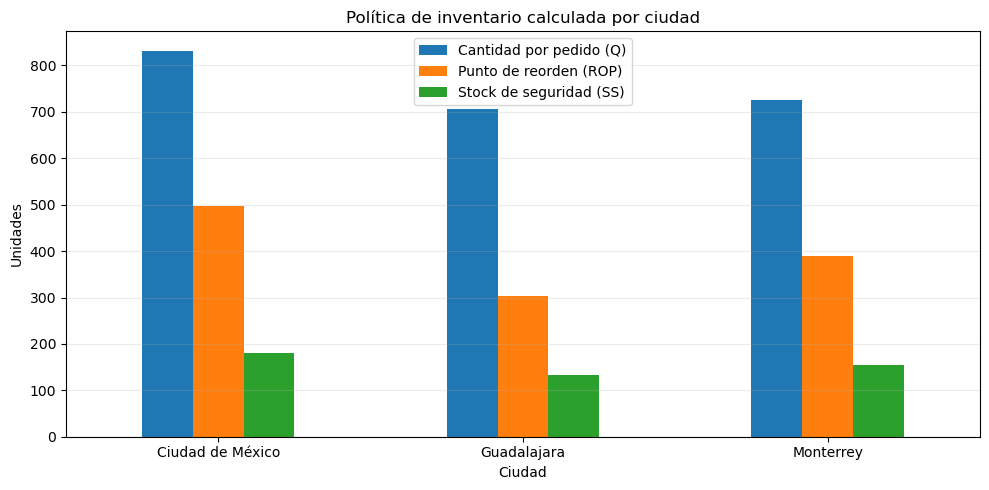

In [36]:
comparacion = politicas.set_index("Ciudad")[["Q_pedido", "ROP", "SS"]]
ax = comparacion.rename(columns={
    "Q_pedido": "Cantidad por pedido (Q)",
    "ROP": "Punto de reorden (ROP)",
    "SS": "Stock de seguridad (SS)",
}).plot(kind="bar", figsize=(10, 5), rot=0)

ax.set_title("Política de inventario calculada por ciudad")
ax.set_xlabel("Ciudad")
ax.set_ylabel("Unidades")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## Fin de la parte 2 — ¿Qué sigue?

Hemos completado los cálculos del **Paso 1.2**: demanda anual estimada, lote económico, stock de seguridad y punto de reorden para las tres ubicaciones. **Todos los costos, plazos e inventarios iniciales son valores hipotéticos editables**, no datos del Excel.

El resultado `politica_por_ciudad` contiene los parámetros calculados y estará disponible en las celdas siguientes.

**Próxima parte (aún no implementada):**
1. Elegir un horizonte de simulación de **n días**.
2. Generar un número uniforme independiente \(U_t\) por día y ciudad, con semilla reproducible.
3. Transformar \(U_t\) en demanda diaria utilizando la tabla `tablas_frecuencia` correspondiente.
4. Actualizar el inventario día por día; controlar pedidos, plazo de entrega y faltantes.
5. Calcular **tres indicadores de desempeño** y generar las gráficas que solicita el PDF.

> **Nota metodológica:** extrapolar desde 283 días supone que la demanda diaria es representativa del resto del año. Es una simplificación que debe quedar documentada en la entrega. El análisis empírico incluye días de demanda cero inferidos por ausencia de pedidos en el archivo.

## Parte 3. Simulación Monte Carlo de la demanda y el inventario

En esta etapa implementaremos los **pasos 2 a 5 del PDF**: generar números uniformes, convertirlos en demanda diaria según las frecuencias acumuladas de cada ciudad y aplicar la política de inventarios calculada con EOQ.

**Supuestos del modelo:** un horizonte de 365 días calendario, semilla fija, una distribución empírica distinta para cada ciudad y tiempos de entrega L constantes. Al inicio de cada día llegan los pedidos programados; luego atendemos la demanda; al final, si la **posición de inventario** es menor o igual al ROP, emitimos un pedido de Q unidades para recibirlo L días después. La posición incluye el inventario disponible **más los pedidos en tránsito**.

**Política de faltantes:** las unidades de demanda que no podemos atender se registran como **ventas perdidas**. No hay pedidos atrasados ni inventario físico negativo. Se admite un pedido nuevo al final de cada día, aunque haya otros pedidos en tránsito.

Estos son **supuestos operativos para nuestra simulación**, no características observadas del archivo de ventas. Los resultados e indicadores finales se examinarán en la siguiente parte.

## Paso 11. Definir el horizonte y la semilla

Simularemos inicialmente **365 días futuros**, comenzando después de la última fecha del Excel. El archivo histórico contiene 283 días: generar 365 días simulados no aumenta artificialmente el historial.

La semilla fija permite reproducir exactamente los mismos números pseudoaleatorios.

In [37]:
N_DIAS = 365
SEMILLA_MONTE_CARLO = 20261016

if not isinstance(N_DIAS, int) or N_DIAS <= 0:
    raise ValueError("N_DIAS debe ser un entero positivo.")

FECHA_INICIO_SIMULACION = pd.Timestamp(demanda_diaria["Fecha"].max()) + pd.Timedelta(days=1)
fechas_simuladas = pd.date_range(start=FECHA_INICIO_SIMULACION, periods=N_DIAS, freq="D")

print(f"Horizonte: {N_DIAS} días por ciudad")
print(f"Semilla: {SEMILLA_MONTE_CARLO}")
print(f"Periodo simulado: {fechas_simuladas[0].date()} a {fechas_simuladas[-1].date()}")

Horizonte: 365 días por ciudad
Semilla: 20261016
Periodo simulado: 2026-10-11 a 2027-10-10


## Paso 12. Transformar números uniformes en demanda aleatoria

**Método de la distribución empírica acumulada:** para cada número uniforme U entre 0 y 1, buscamos el **primer valor de demanda cuya frecuencia relativa acumulada sea mayor o igual que U**.

Por ejemplo, si la demanda de 10 tiene acumulada 0.30 y la de 20 tiene acumulada 0.70, entonces un U = 0.56 produce una demanda simulada de 20 unidades.

Usaremos las tablas de frecuencias ya calculadas. NumPy proporciona un generador de calidad superior al método de cuadrados medios estudiado previamente, y utilizaremos secuencias reproducibles separadas por ciudad.

In [38]:
def generar_demanda_monte_carlo(ciudad, n_dias, generador):
    """Convierte U(0,1) en demandas a partir de la acumulada empírica."""
    tabla = tablas_frecuencia[ciudad]
    valores = tabla["Demanda"].to_numpy(dtype=int)
    acumuladas = tabla["Frecuencia relativa acumulada"].to_numpy(dtype=float)

    if not np.all(np.diff(valores) >= 0):
        raise ValueError(f"La tabla de {ciudad} no está ordenada por demanda.")
    if not np.all(np.diff(acumuladas) >= -1e-12) or not np.isclose(acumuladas[-1], 1.0):
        raise ValueError(f"Las frecuencias acumuladas de {ciudad} no son válidas.")

    # Paso A: generar un U para cada día.
    uniformes = generador.random(n_dias)

    # Paso B: encontrar el primer valor cuya acumulada alcance ese U.
    indices = np.searchsorted(acumuladas, uniformes, side="left")
    indices = np.clip(indices, 0, len(valores) - 1)
    demandas = valores[indices]

    return pd.DataFrame({
        "Ciudad": ciudad,
        "Dia": np.arange(1, n_dias + 1),
        "Fecha": fechas_simuladas,
        "U": uniformes,
        "Demanda_simulada": demandas,
    })


ciudades_simulacion = sorted(tablas_frecuencia)

# Una secuencia pseudoaleatoria reproducible por ciudad.
semillas_ciudad = np.random.SeedSequence(SEMILLA_MONTE_CARLO).spawn(
    len(ciudades_simulacion)
)

partes_demanda = []
for ciudad, semilla_ciudad in zip(ciudades_simulacion, semillas_ciudad):
    rng = np.random.default_rng(semilla_ciudad)
    partes_demanda.append(generar_demanda_monte_carlo(ciudad, N_DIAS, rng))

demandas_simuladas = pd.concat(partes_demanda, ignore_index=True)

assert len(demandas_simuladas) == N_DIAS * len(ciudades_simulacion)
assert demandas_simuladas["U"].between(0, 1, inclusive="left").all()
assert (demandas_simuladas["Demanda_simulada"] >= 0).all()

print("Primeros ocho días simulados por ciudad:")
display(demandas_simuladas.groupby("Ciudad", sort=False).head(8).round({"U": 5}))

comparacion_demanda = (
    demandas_simuladas.groupby("Ciudad")["Demanda_simulada"]
    .mean().rename("Media simulada")
    .to_frame()
    .join(resumen.set_index("Ciudad")["Demanda_media_diaria"].rename("Media histórica"))
)

print("\nComparación de demanda diaria media:")
display(comparacion_demanda.round(2))
print("Las medias simuladas pueden diferir de las históricas debido a la aleatoriedad.")

Primeros ocho días simulados por ciudad:


,Ciudad,Dia,Fecha,U,Demanda_simulada
0,Ciudad de México,1,2026-10-11,0.96005,158
1,Ciudad de México,2,2026-10-12,0.24910,33
2,Ciudad de México,3,2026-10-13,0.07021,0
3,Ciudad de México,4,2026-10-14,0.04871,0
4,Ciudad de México,5,2026-10-15,0.24762,33
5,Ciudad de México,6,2026-10-16,0.61082,77
6,Ciudad de México,7,2026-10-17,0.71873,88
7,Ciudad de México,8,2026-10-18,0.11353,0
365,Guadalajara,1,2026-10-11,0.98845,177
366,Guadalajara,2,2026-10-12,0.96177,129



Comparación de demanda diaria media:


,Media simulada,Media histórica
Ciudad,,
Ciudad de México,63.75,63.16
Guadalajara,43.50,42.88
Monterrey,50.39,46.86


Las medias simuladas pueden diferir de las históricas debido a la aleatoriedad.


## Paso 13. Crear la función que simula el inventario diario

Ya transformamos cada número uniforme U en una demanda diaria. **Ahora toca aplicar el modelo EOQ**.

La función `simular_inventario_ciudad` recibe las demandas simuladas y la política `Q, ROP, SS` de una ciudad. Repite estas operaciones por cada día:

1. **Inventario inicial:** unidades físicas disponibles al comenzar el día (antes de las recepciones).
2. **Recepción:** llegan los pedidos que vencen hoy. Aumenta el inventario físico.
3. **Demanda:** se venden las unidades disponibles y se registran ventas perdidas si la demanda supera lo que tenemos.
4. **Posición de inventario:** inventario físico final + unidades pendientes en tránsito.
5. **Reorden:** si la posición (antes del nuevo pedido) es menor o igual al ROP, se emite un pedido de Q unidades que llegará dentro de L días.
6. **Registro:** guardamos demanda, ventas atendidas, faltantes, inventario final, pedidos y recepciones.

**Convención de tiempo:** un pedido emitido al **final del día t**, con L = 5 días, se recibe al **inicio del día t+5**. Los pedidos recibidos no se cuentan simultáneamente como inventario físico y en tránsito.

**Faltantes:** adoptamos el criterio de **ventas perdidas**; no dejamos inventarios físicos negativos ni acumulamos pedidos atrasados.

Para empezar, suponemos que no había pedidos en tránsito antes del día 1 (así evitamos inventar información sobre órdenes anteriores).

In [39]:
def simular_inventario_ciudad(datos_ciudad, parametros):
    """
    Simula n días de inventario para una ciudad con política (Q, ROP).

    Orden diario: recepciones -> demanda -> comprobación del ROP -> nuevo pedido.
    Si la demanda supera existencias, la parte no atendida se considera venta perdida.
    Se admite como máximo UN pedido nuevo al final de cada día.
    """
    datos_ciudad = datos_ciudad.sort_values("Dia").reset_index(drop=True)
    if datos_ciudad.empty:
        raise ValueError("La ciudad no tiene días simulados.")

    ciudad = str(datos_ciudad.loc[0, "Ciudad"])
    inventario = int(parametros["Inventario_inicial"])
    Q = int(parametros["Q_pedido"])
    ROP = int(parametros["ROP"])
    L = int(parametros["L"])

    if inventario < 0 or Q <= 0 or ROP < 0 or L <= 0:
        raise ValueError(f"Parámetros inválidos para {ciudad}.")

    pedidos_pendientes = []
    historial_pedidos = []
    registros = []

    for fila in datos_ciudad.itertuples(index=False):
        dia = int(fila.Dia)
        fecha = pd.Timestamp(fila.Fecha)
        u = float(fila.U)
        demanda = int(fila.Demanda_simulada)

        if demanda < 0:
            raise ValueError("La demanda no puede ser negativa.")

        # 1. Inventario al empezar el día, ANTES de recibir pedidos.
        inventario_inicial = inventario

        # 2. Recibir los pedidos que llegaron al inicio de este día.
        llegan = [p for p in pedidos_pendientes if p["Dia_recepcion"] == dia]
        recepcion = sum(p["Cantidad"] for p in llegan)
        for p in llegan:
            p["Recibido_en_horizonte"] = True

        pedidos_pendientes = [
            p for p in pedidos_pendientes if p["Dia_recepcion"] > dia
        ]
        inventario += recepcion

        # 3. Atender la demanda, registrando cualquier faltante.
        demanda_atendida = min(demanda, inventario)
        unidades_no_atendidas = demanda - demanda_atendida
        inventario -= demanda_atendida

        # 4. Posición de inventario antes de ordenar.
        pendiente_antes = sum(p["Cantidad"] for p in pedidos_pendientes)
        posicion_antes = inventario + pendiente_antes

        # 5. Emitir un pedido si la posición llegó al punto de reorden.
        pedido_emitido = 0
        fecha_recepcion_programada = pd.NaT
        if posicion_antes <= ROP:
            pedido_emitido = Q
            fecha_recepcion_programada = fecha + pd.Timedelta(days=L)

            nuevo_pedido = {
                "Ciudad": ciudad,
                "Dia_emision": dia,
                "Fecha_emision": fecha,
                "Cantidad": Q,
                "Dia_recepcion": dia + L,
                "Fecha_recepcion": fecha_recepcion_programada,
                "Recibido_en_horizonte": False,
            }
            pedidos_pendientes.append(nuevo_pedido)
            historial_pedidos.append(nuevo_pedido)

        # 6. Registrar el cierre de este día.
        pendiente_final = sum(p["Cantidad"] for p in pedidos_pendientes)
        posicion_final = inventario + pendiente_final

        registros.append({
            "Ciudad": ciudad,
            "Dia": dia,
            "Fecha": fecha,
            "U": u,
            "Inventario_inicial": inventario_inicial,
            "Recepcion": recepcion,
            "Demanda_simulada": demanda,
            "Demanda_atendida": demanda_atendida,
            "Unidades_no_atendidas": unidades_no_atendidas,
            "Inventario_final": inventario,
            "En_transito_final": pendiente_final,
            "Posicion_antes_pedido": posicion_antes,
            "Posicion_final": posicion_final,
            "Pedido_emitido": pedido_emitido,
            "Fecha_recepcion_programada": fecha_recepcion_programada,
        })

    columnas_pedidos = [
        "Ciudad", "Dia_emision", "Fecha_emision", "Cantidad",
        "Dia_recepcion", "Fecha_recepcion", "Recibido_en_horizonte",
    ]

    return (
        pd.DataFrame(registros),
        pd.DataFrame(historial_pedidos, columns=columnas_pedidos),
    )

## Paso 14. Ejecutar la simulación para las tres ciudades

Como cada ciudad tiene una demanda empírica distinta, la simulamos por separado con su propio Q y ROP.

Guardamos:
- `registro_simulacion`: una fila por ciudad y día (inventario, demanda, faltantes, pedidos y recepciones).
- `pedidos_resurtido`: cada pedido emitido, su fecha de emisión, fecha prevista de recepción y si llegó dentro del horizonte.

Después ejecutamos **comprobaciones automáticas** para verificar que el inventario no sea negativo, que no se pierdan unidades en los cálculos y que las órdenes emitidas coincidan con las recibidas o pendientes.

Mostraremos **los primeros 12 días por ciudad**, no los 1,095 registros completos, para facilitar la revisión.

In [40]:
registros_ciudad = []
listas_pedidos = []

for ciudad in ciudades_simulacion:
    entradas = demandas_simuladas.loc[demandas_simuladas["Ciudad"] == ciudad]
    parametros = politica_por_ciudad[ciudad]

    diario, pedidos = simular_inventario_ciudad(entradas, parametros)
    registros_ciudad.append(diario)
    listas_pedidos.append(pedidos)

registro_simulacion = pd.concat(registros_ciudad, ignore_index=True)
pedidos_resurtido = pd.concat(listas_pedidos, ignore_index=True)

# Comprobaciones de coherencia.
assert len(registro_simulacion) == N_DIAS * len(ciudades_simulacion)
assert (registro_simulacion["Inventario_final"] >= 0).all()
assert (registro_simulacion["Unidades_no_atendidas"] >= 0).all()
assert (
    registro_simulacion["Demanda_simulada"]
    == registro_simulacion["Demanda_atendida"]
    + registro_simulacion["Unidades_no_atendidas"]
).all(), "La demanda no coincide con lo atendido más lo no atendido."
assert (
    registro_simulacion["Inventario_final"]
    == registro_simulacion["Inventario_inicial"]
    + registro_simulacion["Recepcion"]
    - registro_simulacion["Demanda_atendida"]
).all(), "El balance físico del inventario es incorrecto."
assert (
    registro_simulacion["Posicion_final"]
    == registro_simulacion["Inventario_final"]
    + registro_simulacion["En_transito_final"]
).all(), "La posición de inventario es incorrecta."

# Balance de las unidades solicitadas por ciudad.
for ciudad in ciudades_simulacion:
    df_ciudad = registro_simulacion[registro_simulacion["Ciudad"] == ciudad]
    emitidas = int(df_ciudad["Pedido_emitido"].sum())
    recibidas = int(df_ciudad["Recepcion"].sum())
    pendientes = int(df_ciudad.iloc[-1]["En_transito_final"])
    assert emitidas == recibidas + pendientes, (
        f"Los pedidos de {ciudad} no cuadran con recepciones y tránsito."
    )

print(f"Registros diarios generados: {len(registro_simulacion)}")
print(f"Órdenes de resurtido emitidas: {len(pedidos_resurtido)}")

columnas_muestra = [
    "Dia", "Fecha", "U", "Inventario_inicial", "Recepcion",
    "Demanda_simulada", "Demanda_atendida", "Unidades_no_atendidas",
    "Inventario_final", "Posicion_final", "Pedido_emitido",
    "Fecha_recepcion_programada",
]
for ciudad in ciudades_simulacion:
    print(f"\nPRIMEROS 12 DÍAS: {ciudad}")
    muestra = registro_simulacion[registro_simulacion["Ciudad"] == ciudad]
    display(muestra[columnas_muestra].head(12).round({"U": 5}))

print("\nPRIMEROS PEDIDOS DE RESURTIDO:")
display(pedidos_resurtido.head(12))
print("\nPruebas de coherencia superadas.")

Registros diarios generados: 1095
Órdenes de resurtido emitidas: 77

PRIMEROS 12 DÍAS: Ciudad de México


,Dia,Fecha,U,Inventario_inicial,Recepcion,Demanda_simulada,Demanda_atendida,Unidades_no_atendidas,Inventario_final,Posicion_final,Pedido_emitido,Fecha_recepcion_programada
0,1,2026-10-11,0.96005,550,0,158,158,0,392,1224,832,2026-10-16
1,2,2026-10-12,0.24910,392,0,33,33,0,359,1191,0,NaT
2,3,2026-10-13,0.07021,359,0,0,0,0,359,1191,0,NaT
3,4,2026-10-14,0.04871,359,0,0,0,0,359,1191,0,NaT
4,5,2026-10-15,0.24762,359,0,33,33,0,326,1158,0,NaT
5,6,2026-10-16,0.61082,326,832,77,77,0,1081,1081,0,NaT
6,7,2026-10-17,0.71873,1081,0,88,88,0,993,993,0,NaT
7,8,2026-10-18,0.11353,993,0,0,0,0,993,993,0,NaT
8,9,2026-10-19,0.72568,993,0,89,89,0,904,904,0,NaT
9,10,2026-10-20,0.93505,904,0,147,147,0,757,757,0,NaT



PRIMEROS 12 DÍAS: Guadalajara


,Dia,Fecha,U,Inventario_inicial,Recepcion,Demanda_simulada,Demanda_atendida,Unidades_no_atendidas,Inventario_final,Posicion_final,Pedido_emitido,Fecha_recepcion_programada
365,1,2026-10-11,0.98845,400,0,177,177,0,223,929,706,2026-10-15
366,2,2026-10-12,0.96177,223,0,129,129,0,94,800,0,NaT
367,3,2026-10-13,0.12407,94,0,0,0,0,94,800,0,NaT
368,4,2026-10-14,0.59620,94,0,42,42,0,52,758,0,NaT
369,5,2026-10-15,0.48980,52,706,34,34,0,724,724,0,NaT
370,6,2026-10-16,0.73825,724,0,60,60,0,664,664,0,NaT
371,7,2026-10-17,0.35674,664,0,26,26,0,638,638,0,NaT
372,8,2026-10-18,0.24168,638,0,7,7,0,631,631,0,NaT
373,9,2026-10-19,0.98764,631,0,177,177,0,454,454,0,NaT
374,10,2026-10-20,0.52708,454,0,36,36,0,418,418,0,NaT



PRIMEROS 12 DÍAS: Monterrey


,Dia,Fecha,U,Inventario_inicial,Recepcion,Demanda_simulada,Demanda_atendida,Unidades_no_atendidas,Inventario_final,Posicion_final,Pedido_emitido,Fecha_recepcion_programada
730,1,2026-10-11,0.64670,450,0,57,57,0,393,393,0,NaT
731,2,2026-10-12,0.19453,393,0,0,0,0,393,393,0,NaT
732,3,2026-10-13,0.00539,393,0,0,0,0,393,393,0,NaT
733,4,2026-10-14,0.55267,393,0,45,45,0,348,1073,725,2026-10-19
734,5,2026-10-15,0.99767,348,0,173,173,0,175,900,0,NaT
735,6,2026-10-16,0.62434,175,0,52,52,0,123,848,0,NaT
736,7,2026-10-17,0.97408,123,0,140,123,17,0,725,0,NaT
737,8,2026-10-18,0.60169,0,0,49,0,49,0,725,0,NaT
738,9,2026-10-19,0.25472,0,725,0,0,0,725,725,0,NaT
739,10,2026-10-20,0.20746,725,0,0,0,0,725,725,0,NaT



PRIMEROS PEDIDOS DE RESURTIDO:


,Ciudad,Dia_emision,Fecha_emision,Cantidad,Dia_recepcion,Fecha_recepcion,Recibido_en_horizonte
0,Ciudad de México,1,2026-10-11,832,6,2026-10-16,True
1,Ciudad de México,14,2026-10-24,832,19,2026-10-29,True
2,Ciudad de México,26,2026-11-05,832,31,2026-11-10,True
3,Ciudad de México,36,2026-11-15,832,41,2026-11-20,True
4,Ciudad de México,50,2026-11-29,832,55,2026-12-04,True
5,Ciudad de México,61,2026-12-10,832,66,2026-12-15,True
6,Ciudad de México,73,2026-12-22,832,78,2026-12-27,True
7,Ciudad de México,88,2027-01-06,832,93,2027-01-11,True
8,Ciudad de México,102,2027-01-20,832,107,2027-01-25,True
9,Ciudad de México,118,2027-02-05,832,123,2027-02-10,True



Pruebas de coherencia superadas.


## Paso 15. Graficar la evolución del inventario

Por último, mostraremos los primeros 90 días (o menos, si el horizonte es menor) de cada ciudad.

- **Inventario físico final:** mercancía disponible.
- **Posición final:** inventario disponible más mercancía pendiente de recibir.
- **ROP:** referencia para decidir cuándo hacer un pedido. **Se compara con la posición de inventario antes de ordenar, no con la cantidad física del almacén.**
- **SS:** cantidad de seguridad que se incluyó en el cálculo del ROP.

En esta misma gráfica marcamos días en que se emitieron pedidos y en que se recibió mercancía. Los cálculos de costos y servicio se harán en el **siguiente paso de la actividad**, una vez que validemos estos registros.

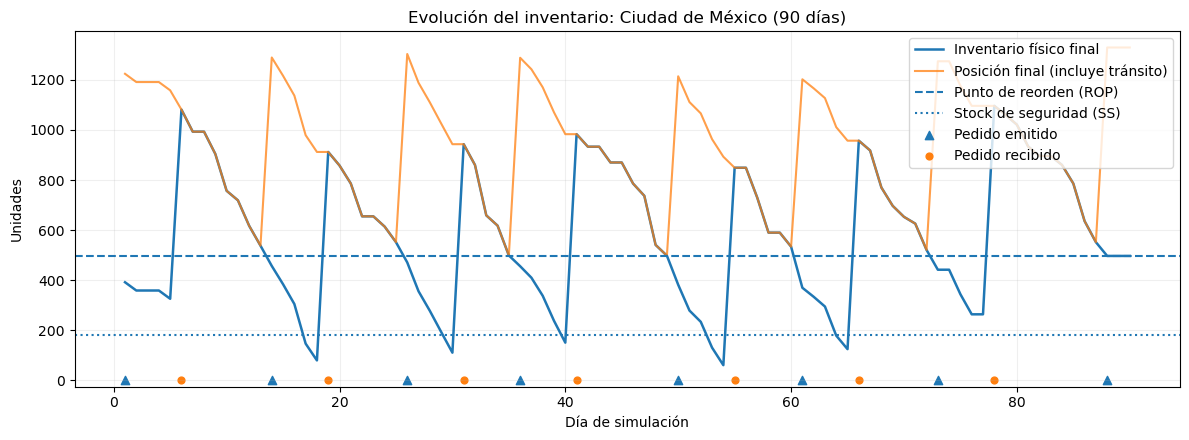

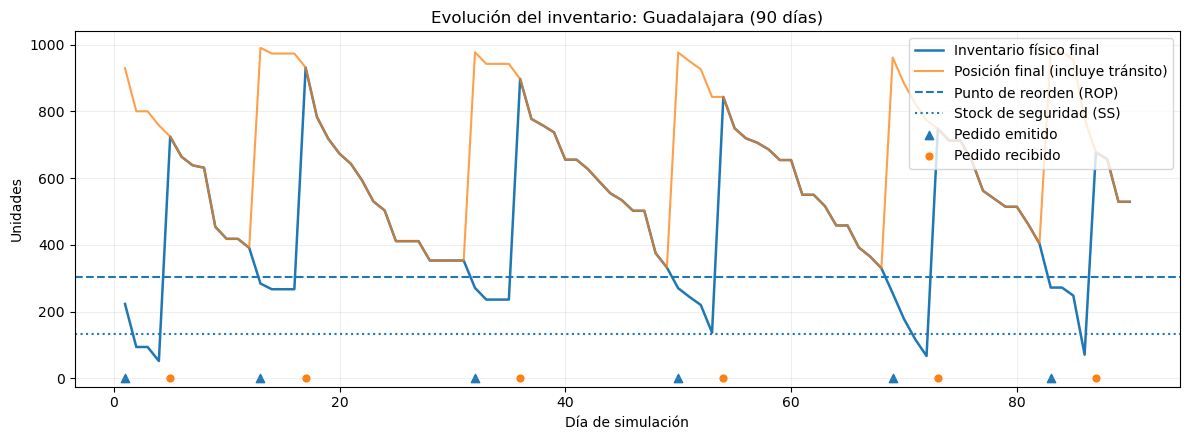

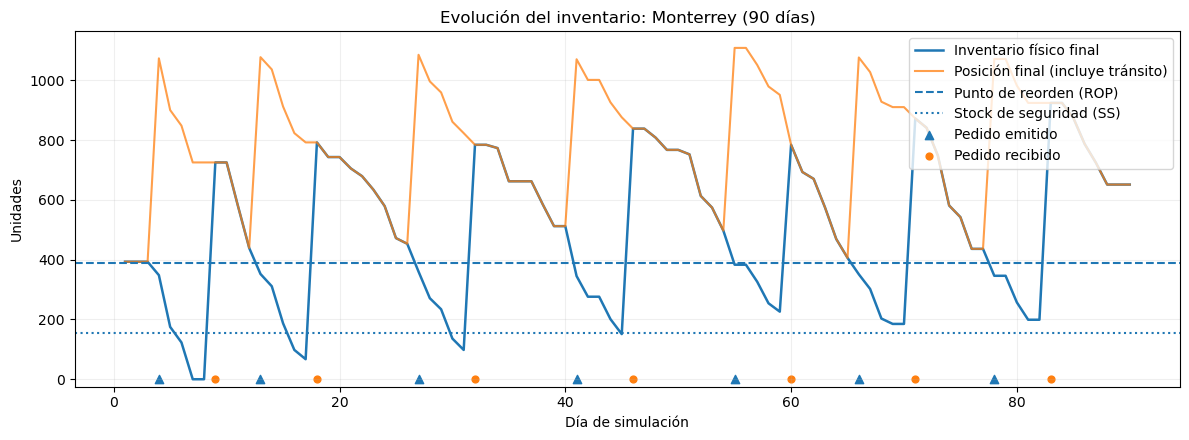

In [41]:
DIAS_GRAFICA = min(90, N_DIAS)

for ciudad in ciudades_simulacion:
    df_ciudad = registro_simulacion.loc[
        (registro_simulacion["Ciudad"] == ciudad)
        & (registro_simulacion["Dia"] <= DIAS_GRAFICA)
    ]
    politica = politica_por_ciudad[ciudad]

    fig, ax = plt.subplots(figsize=(12, 4.5))
    ax.plot(df_ciudad["Dia"], df_ciudad["Inventario_final"],
            label="Inventario físico final", linewidth=1.8)
    ax.plot(df_ciudad["Dia"], df_ciudad["Posicion_final"],
            label="Posición final (incluye tránsito)", alpha=0.75)
    ax.axhline(politica["ROP"], linestyle="--", label="Punto de reorden (ROP)")
    ax.axhline(politica["SS"], linestyle=":", label="Stock de seguridad (SS)")

    dias_pedido = df_ciudad.loc[df_ciudad["Pedido_emitido"] > 0, "Dia"]
    dias_recepcion = df_ciudad.loc[df_ciudad["Recepcion"] > 0, "Dia"]
    ax.scatter(dias_pedido, np.zeros(len(dias_pedido)),
               marker="^", s=36, label="Pedido emitido")
    ax.scatter(dias_recepcion, np.zeros(len(dias_recepcion)),
               marker="o", s=24, label="Pedido recibido")

    ax.set_title(f"Evolución del inventario: {ciudad} ({DIAS_GRAFICA} días)")
    ax.set_xlabel("Día de simulación")
    ax.set_ylabel("Unidades")
    ax.set_ylim(bottom=-25)
    ax.grid(alpha=0.2)
    ax.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

## Conclusión de la parte 3 y siguiente paso

Ya tenemos una **simulación Monte Carlo de inventario** para las tres ciudades:

- Se generan números pseudoaleatorios \(U(0,1)\) con semilla fija.
- Se convierten mediante las frecuencias relativas acumuladas del Excel en demandas diarias.
- Se atiende cada demanda, se registran las ventas perdidas y se mantiene el inventario físico no negativo.
- Se emiten pedidos EOQ según la posición de inventario y el ROP, y se registran sus fechas de recepción.
- Se comprueban las igualdades de balance y se trazan las gráficas diarias.

**Próximo paso (Paso 6 del PDF):** calcular tres indicadores de desempeño que permitan comparar las ciudades: por ejemplo, **nivel de servicio por unidades**, **número de pedidos** y **costo total de ordenar y mantener durante la simulación**. El costo de los faltantes requeriría un parámetro adicional que no proporciona el Excel.

La demanda simulada deriva de la distribución empírica del periodo histórico (283 días). No sabemos si es totalmente representativa de un año futuro; nuestros resultados dependen de esa hipótesis y de los valores de costo y plazo establecidos en la parte 2.

## Parte 4 — Paso 6 del PDF: indicadores de desempeño

La actividad solicita elegir **tres indicadores principales**. Elegimos:
1. **Nivel de servicio por unidades (%)**: proporción de unidades demandadas que sí se entregaron.
2. **Número de pedidos**: cantidad de órdenes de resurtido emitidas.
3. **Costo total simulado (MXN)**: costo de ordenar, mantener y penalizar faltantes.

También reportamos como **diagnóstico** la demanda total, inventario promedio, días con faltantes, unidades no atendidas, cantidades recibidas y desglose de costos.

El PDF pide gráficas de demanda diaria, inventario y sus referencias ROP/SS, emisión/recepción de órdenes y comparación de costos, servicio y faltantes. Las agregaremos en los siguientes pasos.

**Importante:** costos y plazos son supuestos del ejercicio. Las tres ciudades tienen demandas distintas: no basta comparar el costo absoluto para decir cuál opera mejor.

## Paso 16. Definir un costo de faltantes editable

El PDF permite incorporar los costos por faltantes **si se modelan**. Nuestro Excel no trae ese dato, así que introducimos una penalización **hipotética de 80 MXN por unidad no atendida** para cada ciudad.

En este modelo, los faltantes son **ventas perdidas** (no pedidos atrasados). Esta penalización **no es un precio de venta extraído del Excel** y se puede ajustar antes de ejecutar la simulación.

Usaremos costos sobre el mismo horizonte de tiempo:
- Costo de ordenar: número de pedidos por costo fijo S.
- Costo de mantener: suma del inventario físico final diario multiplicada por H/365, dado que H está expresado por año.
- Costo de faltantes: unidades no atendidas por penalización unitaria.
- Costo total: suma de los tres.

No incluimos costos de compra porque no contamos con un precio unitario de compra.

In [ ]:
# Parámetro hipotético y editable (MXN por unidad no atendida).
COSTO_FALTANTE_UNITARIO = {
    "Ciudad de México": 80.0,
    "Guadalajara": 80.0,
    "Monterrey": 80.0,
}

if set(COSTO_FALTANTE_UNITARIO) != set(ciudades_simulacion):
    raise ValueError("Falta definir el costo unitario de faltantes para alguna ciudad.")
if not all(np.isfinite(x) and x >= 0 for x in COSTO_FALTANTE_UNITARIO.values()):
    raise ValueError("Los costos unitarios de faltantes deben ser no negativos.")

costos_faltantes = pd.DataFrame([
    {"Ciudad": ciudad, "Costo_faltante_unitario": importe}
    for ciudad, importe in COSTO_FALTANTE_UNITARIO.items()
])

print("Costo hipotético de faltantes, en MXN por unidad:")
display(costos_faltantes)

## Paso 17. Calcular los tres indicadores y las medidas de diagnóstico

**Nivel de servicio por unidades**: 100 multiplicado por (1 - unidades no atendidas / demanda total). Si toda la demanda fue cero, la razón está indefinida.

**Número de pedidos**: contamos todos los pedidos que se emitieron, incluso los que aún no llegaron al finalizar el horizonte.

**Costo total simulado**: costo de ordenar más costo de mantener más penalización por faltantes. Como nuestro horizonte inicial es de 365 días calendario, convertimos el costo anual H a su equivalente diario H/365. Si cambiamos el horizonte, el costo de mantener se adapta automáticamente.

In [ ]:
# Resumir el registro de los n días simulados por ciudad.
diagnosticos = (
    registro_simulacion.groupby("Ciudad")
    .agg(
        Dias_simulados=("Dia", "count"),
        Demanda_total_simulada=("Demanda_simulada", "sum"),
        Demanda_media_simulada=("Demanda_simulada", "mean"),
        Demanda_atendida=("Demanda_atendida", "sum"),
        Unidades_no_atendidas=("Unidades_no_atendidas", "sum"),
        Dias_con_faltantes=("Unidades_no_atendidas", lambda s: int((s > 0).sum())),
        Inventario_promedio=("Inventario_final", "mean"),
        Inventario_minimo=("Inventario_final", "min"),
        Numero_pedidos=("Pedido_emitido", lambda s: int((s > 0).sum())),
        Unidades_pedidas=("Pedido_emitido", "sum"),
        Unidades_recibidas=("Recepcion", "sum"),
    )
    .reset_index()
)

# Unimos los parámetros de costos definidos anteriormente.
indicadores = (
    diagnosticos.merge(
        parametros_ciudad[["Ciudad", "S", "H"]],
        on="Ciudad", validate="one_to_one"
    )
    .merge(costos_faltantes, on="Ciudad", validate="one_to_one")
)

# Indicador 1: unidades atendidas sobre el total demandado.
indicadores["Nivel_servicio_pct"] = np.where(
    indicadores["Demanda_total_simulada"] > 0,
    100 * indicadores["Demanda_atendida"]
    / indicadores["Demanda_total_simulada"].replace(0, np.nan),
    np.nan,
)

# Indicador 2: número de pedidos, ya obtenido del registro diario.

# Indicador 3: todos los costos referidos al periodo simulado.
indicadores["Costo_ordenar"] = indicadores["Numero_pedidos"] * indicadores["S"]
indicadores["Costo_mantener"] = (
    indicadores["Inventario_promedio"]
    * indicadores["Dias_simulados"] * indicadores["H"] / DIAS_POR_ANIO
)
indicadores["Costo_faltantes"] = (
    indicadores["Unidades_no_atendidas"] * indicadores["Costo_faltante_unitario"]
)
indicadores["Costo_total_simulado"] = (
    indicadores["Costo_ordenar"]
    + indicadores["Costo_mantener"]
    + indicadores["Costo_faltantes"]
)

# Pruebas automáticas de consistencia.
assert (indicadores["Inventario_minimo"] >= 0).all()
assert (indicadores["Numero_pedidos"] >= 0).all()
assert indicadores["Nivel_servicio_pct"].dropna().between(0, 100).all()
assert (
    indicadores["Demanda_total_simulada"]
    == indicadores["Demanda_atendida"] + indicadores["Unidades_no_atendidas"]
).all()
assert np.allclose(
    indicadores["Costo_total_simulado"],
    indicadores["Costo_ordenar"]
    + indicadores["Costo_mantener"] + indicadores["Costo_faltantes"]
)

recuento_ordenes = (
    pedidos_resurtido.groupby("Ciudad").size()
    .reindex(indicadores["Ciudad"], fill_value=0).to_numpy()
)
assert np.array_equal(indicadores["Numero_pedidos"].to_numpy(), recuento_ordenes)

print("TRES INDICADORES PRINCIPALES")
display(indicadores[
    ["Ciudad", "Nivel_servicio_pct", "Numero_pedidos", "Costo_total_simulado"]
].round(2))

print("\nMEDIDAS DE DIAGNÓSTICO")
display(indicadores[
    ["Ciudad", "Dias_simulados", "Demanda_total_simulada",
     "Demanda_media_simulada", "Inventario_promedio", "Inventario_minimo",
     "Dias_con_faltantes", "Unidades_no_atendidas",
     "Unidades_pedidas", "Unidades_recibidas"]
].round(2))

print("\nCOSTOS DESGLOSADOS (MXN)")
display(indicadores[
    ["Ciudad", "Costo_ordenar", "Costo_mantener",
     "Costo_faltantes", "Costo_total_simulado"]
].round(2))

print("\nComprobaciones superadas: demanda, pedidos y costos.")
